# 2048: Minimax con poda alpha-beta y Expectimax

Resumen de los experimentos. Para reproducirlos:

```bash
python experiments.py --suite all   # ~1 h con 2 núcleos
python make_figures.py
```

In [1]:
import json, sys, time
from pathlib import Path
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from game2048 import ExpectimaxAgent, GameBoard, MinimaxAgent, MOVE_NAMES, play_game
from game2048.heuristics import PRESETS, Evaluator

def table(suite):
    res = json.loads((ROOT / "results" / f"{suite}.json").read_text())["results"]
    cols = ["games", "win_rate", "max_tile_median", "score_mean", "moves_mean", "ms_per_move_mean", "nodes_per_move_mean"]
    return pd.DataFrame({k: v["summary"] for k, v in res.items()}).T[cols]

## 1. Agentes y profundidad

,games,win_rate,max_tile_median,score_mean,moves_mean,ms_per_move_mean,nodes_per_move_mean
random,100,0.0,128.0,1089.4,118.2,0.026,0.0
minimax_ab_d1,30,0.0,256.0,4281.2,338.9,0.093,26.3
minimax_ab_d2,30,0.167,1024.0,14024.1,821.6,1.748,675.4
minimax_ab_d3,10,0.3,1024.0,16504.4,913.6,37.373,15004.2
expectimax_d1,30,0.0,256.0,4737.6,366.1,0.131,42.8
expectimax_d2,30,0.367,1024.0,18031.6,994.8,5.48,2177.2
expectimax_d3_p1e-3,10,0.8,2048.0,19757.6,982.2,88.39,33850.1


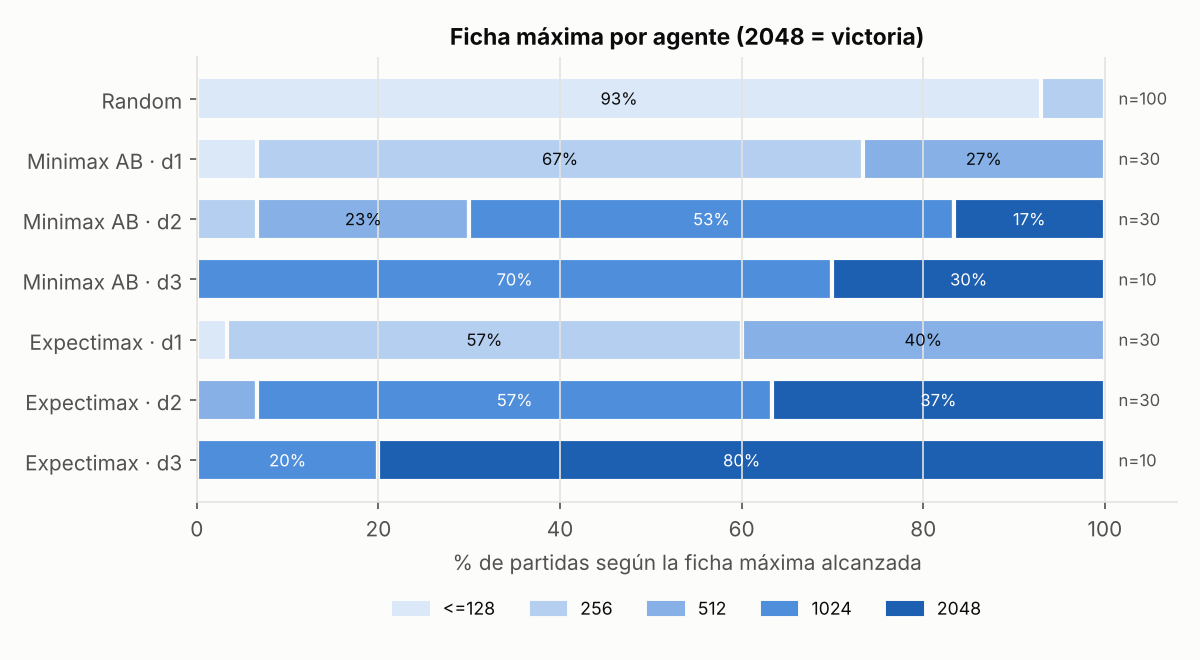

In [2]:
display(table("agents")); display(Image(ROOT / "figures" / "agentes_ficha_maxima.png"))

## 2. Impacto de la poda alpha-beta

Mismas 100 posiciones de medio juego, con y sin poda. La poda no cambia ninguna decisión.

,positions,plain_nodes_per_position,plain_ms_per_position,ab_nodes_per_position,ab_ms_per_position,prunings_per_position,same_decisions,node_reduction_pct,speedup
depth,,,,,,,,,
1,100,38.1,0.101,27.3,0.091,1.3,True,28.3,1.11
2,100,1661.8,4.615,601.7,1.670,39.1,True,63.8,2.76
3,100,77888.0,201.180,11981.6,33.915,841.3,True,84.6,5.93


Partidas completas idénticas con y sin poda: True


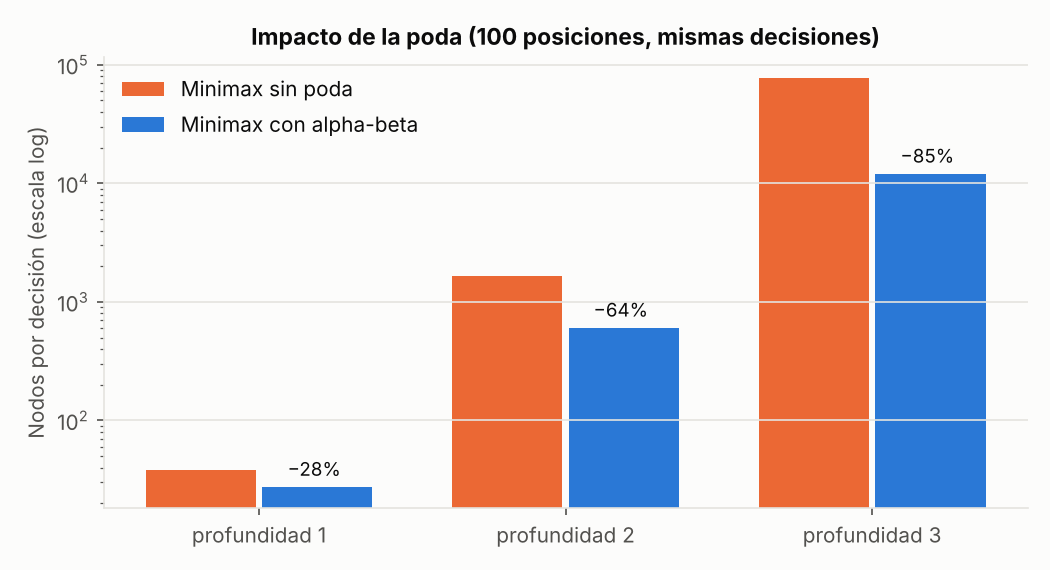

In [3]:
ab = json.loads((ROOT / "results" / "alphabeta.json").read_text())["results"]
display(pd.DataFrame(ab["positions"]).set_index("depth"))
print("Partidas completas idénticas con y sin poda:", ab["full_games_identical"])
display(Image(ROOT / "figures" / "alpha_beta_nodos.png"))

## 3. Funciones de evaluación

,smooth,empty,mono,max_tile,sumsq,corner
original,0.1,2.7,1.0,1.0,0.01,0.5
balanceada,0.1,2.7,1.0,1.0,0.00,0.5
solo_vacias,0.0,1.0,0.0,0.0,0.00,0.0
solo_sumsq,0.0,0.0,0.0,0.0,1.00,0.0
enfasis_vacias,0.1,5.0,1.0,1.0,0.00,0.5
enfasis_mono,0.1,2.7,3.0,1.0,0.00,0.5
mono_y_vacias,0.5,4.0,3.0,0.0,0.00,1.0


,games,win_rate,max_tile_median,score_mean,moves_mean,ms_per_move_mean,nodes_per_move_mean
original,20,0.3,1024.0,15520.6,858.8,6.574,2513.5
balanceada,20,0.45,1024.0,18053.4,980.1,5.761,2172.6
solo_vacias,20,0.0,512.0,7652.0,506.2,4.968,2692.3
solo_sumsq,20,0.0,768.0,10016.6,628.7,4.601,2445.1
enfasis_vacias,20,0.35,1024.0,16181.8,894.6,6.438,2400.5
enfasis_mono,20,0.2,1024.0,15653.6,900.4,4.796,1863.4
mono_y_vacias,20,0.5,1536.0,19053.4,1018.2,5.492,1999.5


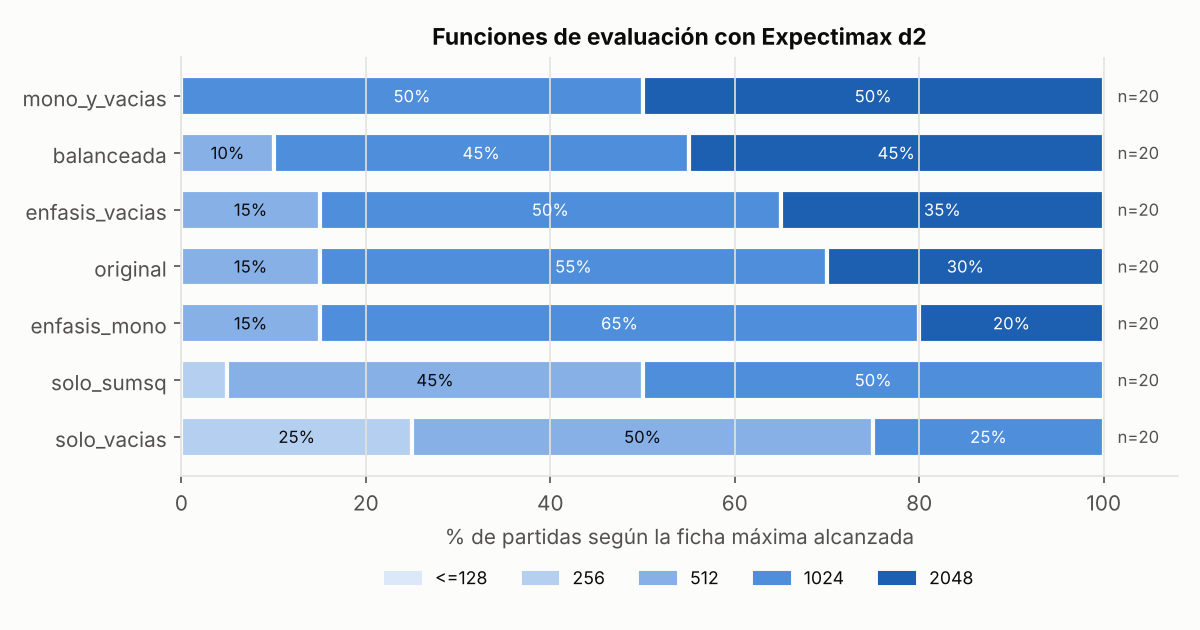

In [4]:
display(pd.DataFrame({k: w.to_dict() for k, w in PRESETS.items()}).T)
display(table("heuristics")); display(Image(ROOT / "figures" / "heuristicas.png"))

## 4. Cómo decide el agente en una posición

In [5]:
board = GameBoard(seed=42)
for _ in range(40):
    board.play(ExpectimaxAgent(depth=1).play(board))
board.render()
ev = Evaluator(PRESETS["balanceada"])
print("Componentes de la heurística:", {k: round(v, 1) for k, v in ev.components(board.board).items()})
for agent in (ExpectimaxAgent(depth=2), MinimaxAgent(depth=2, use_alpha_beta=True)):
    t = time.perf_counter(); move = agent.play(board)
    print(f"{agent.name:<16} elige {MOVE_NAMES[move]:<5} | {agent.nodes_explored} nodos | {(time.perf_counter()-t)*1000:.0f} ms")

     0       0       0       2  
     0       0       4       8  
     2       0       4      16  
     0       8      16      32  

Componentes de la heurística: {'smooth': -11.0, 'empty': 7.0, 'mono': -2.0, 'max_tile': 5.0, 'sumsq': 1704.0, 'corner': 5.0}
expectimax_d2    elige RIGHT | 3181 nodos | 7 ms
minimax_ab_d2    elige RIGHT | 1091 nodos | 3 ms


## 5. Una partida completa

In [6]:
stats = play_game(ExpectimaxAgent(depth=2), seed=0)
stats

{'seed': 0,
 'moves': 1030,
 'max_tile': 1024,
 'score': 17028,
 'tile_sum': 2248,
 'won': False,
 'seconds': 5.72,
 'ms_per_move': 5.553,
 'nodes': 2331448,
 'nodes_per_move': 2263.5}